# Application export: EDA

Profile of `data/raw_applications.csv` and of the prototype's behaviour on it. Conclusions: [FINDINGS.md](FINDINGS.md).

## 1. Load

Every field is read as text, so blanks and `NA`/`null` stay visible.

In [1]:
from pathlib import Path
from decimal import Decimal, InvalidOperation
import importlib.util
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
sys.dont_write_bytecode = True   # importing the prototype must not write __pycache__ into reference/

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'data/raw_applications.csv').is_file())
raw = pd.read_csv(ROOT / 'data/raw_applications.csv', dtype=str, keep_default_na=False)
print(f'{len(raw)} rows; {len(raw.columns)} columns')
display(raw[['application_id', 'company_name', 'tax_id', 'employees',
             'annual_revenue', 'requested_amount', 'source_system']].head(3))

196 rows; 12 columns


,application_id,company_name,tax_id,employees,annual_revenue,requested_amount,source_system
0,RAW-0073,Company 0073 S.L.,H30261375,10,1441971.18,175311.57,legacy_crm
1,RAW-0043,Company 0043 S.L.,H69062738,19,3225.09,280516.32,new_partner_feed
2,RAW-0156,Company 0156 S.L.,H80042744,,4411183.42,414549.77,legacy_crm


## 2. Data quality

Blank, `NA`, `N/A` and `null` count as missing.

In [2]:
missing_tokens = {'', 'na', 'n/a', 'null'}
numeric_fields = ['employees', 'annual_revenue', 'annual_ebitda', 'requested_amount']
missing = raw.apply(lambda col: col.str.strip().str.lower().isin(missing_tokens))
numeric = raw[numeric_fields].mask(missing[numeric_fields]).apply(pd.to_numeric, errors='coerce')
quality = pd.DataFrame({
    'missing': missing[numeric_fields].sum(),
    'unparseable_nonmissing': (numeric.isna() & ~missing[numeric_fields]).sum(),
    'zero': numeric.eq(0).sum(),
    'negative': numeric.lt(0).sum(),
    'minimum': numeric.min(), 'median': numeric.median(), 'maximum': numeric.max()
})
display(quality.round(2))

dates = raw['incorporation_date']
slash_dates = dates.str.fullmatch(r'\d{2}/\d{2}/\d{4}')
ambiguous_dates = dates[slash_dates].map(
    lambda s: int(s[:2]) <= 12 and int(s[3:5]) <= 12 and s[:2] != s[3:5])
ebitda_above_revenue = numeric['annual_ebitda'] > numeric['annual_revenue']
print(f'Dates: {missing["incorporation_date"].sum()} missing; '
      f'{slash_dates.sum()} slash-formatted; {ambiguous_dates.sum()} day/month-ambiguous.')
print(f'EBITDA above revenue: {ebitda_above_revenue.sum()} rows (investigate definitions).')
print('Employee extreme:', numeric['employees'].max())

,missing,unparseable_nonmissing,zero,negative,minimum,median,maximum
employees,22,0,2,1,-3.00,18.00,50000.00
annual_revenue,0,0,0,0,1412.69,2884566.27,9768924.45
annual_ebitda,101,0,0,10,-576795.15,155652.13,743961.97
requested_amount,0,0,0,0,3048.35,237289.14,1443747.70


Dates: 10 missing; 30 slash-formatted; 10 day/month-ambiguous.
EBITDA above revenue: 5 rows (investigate definitions).
Employee extreme: 50000.0


## 3. Identity and duplicates

Tax IDs are normalized (case, separators) to find repeated companies.

In [3]:
normalized = raw.assign(tax_id_normalized=raw['tax_id'].str.strip().str.upper()
                        .str.replace(r'[-\s]', '', regex=True))
assert normalized['tax_id_normalized'].str.fullmatch(r'[A-Z0-9]+').all()
same_company_fields = [c for c in raw.columns if c not in ['application_id', 'tax_id']]
conflicts = normalized.groupby('tax_id_normalized')[same_company_fields].nunique().gt(1)
assert not conflicts.any().any(), 'Conflicting company records: resolve before collapsing.'
companies = normalized.drop_duplicates('tax_id_normalized').copy()
exact_extras = int(raw.duplicated().sum())
other_extras = len(raw) - exact_extras - len(companies)
display(pd.DataFrame({
    'metric': ['Raw records', 'Distinct application IDs', 'Extra exact copies',
               'Additional repeated-company rows', 'Normalized company identifiers'],
    'count': [len(raw), raw.application_id.nunique(), exact_extras, other_extras, len(companies)]
}))
repeats = normalized.groupby('tax_id_normalized').agg(
    rows=('application_id', 'size'),
    application_ids=('application_id', lambda s: ', '.join(sorted(set(s)))),
    tax_id_forms=('tax_id', lambda s: ', '.join(sorted(set(s)))))
display(repeats[repeats.rows > 1].head(4))

,metric,count
0,Raw records,196
1,Distinct application IDs,192
2,Extra exact copies,4
3,Additional repeated-company rows,12
4,Normalized company identifiers,180


,rows,application_ids,tax_id_forms
tax_id_normalized,,,
A54437256,2,"RAW-0151, RAW-0151-DUP","A-54437256, A54437256"
A58384270,2,"RAW-0010, RAW-0010-DUP","A-58384270, A58384270"
A61671103,2,"RAW-0024, RAW-0024-DUP","A-61671103, A61671103"
A66045067,2,"RAW-0077, RAW-0077-DUP","A-66045067, A66045067"


## 4. The prototype (v1) on this data

v1 calls an application high risk when revenue per employee is below 40,000 or the request is above 20% of revenue.
First the supplied function as is, then the same rules behind a data check: missing, zero or negative inputs are
not scored.

In [4]:
spec = importlib.util.spec_from_file_location('supplied_prototype', ROOT / 'reference/risk_scoring_prototype.py')
prototype = importlib.util.module_from_spec(spec)
spec.loader.exec_module(prototype)

def original_result(row):
    try:
        return prototype.score_row(row)
    except (ValueError, ZeroDivisionError) as exc:
        return type(exc).__name__

def evaluate(row, requested_ceiling=Decimal('0.20')):
    values = {}
    for field in ['annual_revenue', 'employees', 'requested_amount']:
        text = str(row[field]).strip()
        if text.lower() in missing_tokens:
            return 'needs_data', 'missing_' + field
        try:
            value = Decimal(text)
        except InvalidOperation:
            return 'needs_review', 'invalid_' + field
        if not value.is_finite() or value < 0:
            return 'needs_review', 'invalid_' + field
        if value == 0:
            return 'needs_data', 'unsupported_zero_' + field
        values[field] = value
    revenue, employees, amount = [values[k] for k in ['annual_revenue', 'employees', 'requested_amount']]
    if employees != employees.to_integral_value():
        return 'needs_review', 'headcount_definition_required'
    reasons = []
    if revenue < Decimal('40000') * employees:
        reasons.append('low_revenue_per_employee')
    if amount > requested_ceiling * revenue:
        reasons.append('high_requested_to_revenue')
    return ('high_risk', '; '.join(reasons)) if reasons else ('low_risk', 'within_thresholds')

original = raw.apply(original_result, axis=1)
gated_raw = raw.apply(lambda row: evaluate(row)[0], axis=1)
companies[['v1', 'reason_v1']] = companies.apply(lambda row: pd.Series(evaluate(row)), axis=1)
counts = pd.concat([
    original.value_counts().rename(f'original: {len(raw)} raw rows'),
    gated_raw.value_counts().rename(f'input gate: {len(raw)} raw rows'),
    companies.v1.value_counts().rename(f'input gate: {len(companies)} company records')
], axis=1).fillna(0).astype(int)
display(counts)
eligible = companies[companies.v1.isin(['low_risk', 'high_risk'])].copy()
assert eligible.apply(original_result, axis=1).eq(eligible.v1).all()
print('Parity with supplied rules on eligible company records:', len(eligible), 'of', len(eligible))
display(raw.loc[numeric.employees.lt(0), ['application_id', 'employees']]
        .assign(original_result=original[numeric.employees.lt(0)].values,
                proposed_state=gated_raw[numeric.employees.lt(0)].values))

,original: 196 raw rows,input gate: 196 raw rows,input gate: 180 company records
low_risk,158,158,146
ValueError,22,0,0
high_risk,14,13,13
ZeroDivisionError,2,0,0
needs_data,0,24,20
needs_review,0,1,1


Parity with supplied rules on eligible company records: 159 of 159


,application_id,employees,original_result,proposed_state
96,RAW-0017,-3,high_risk,needs_review


,rows,missing_employees,missing_pct
source_system,,,
legacy_crm,73,13,17.8
manual_entry,58,3,5.2
new_partner_feed,65,6,9.2


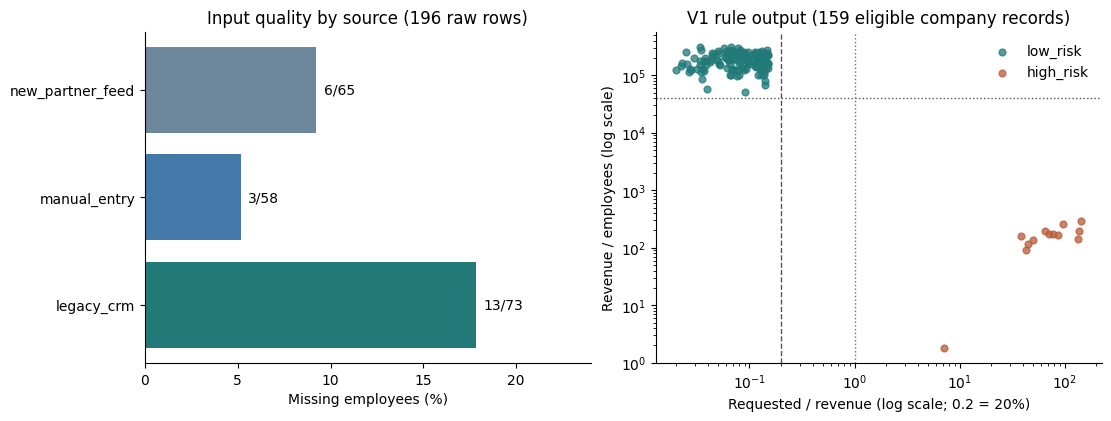

In [5]:
source_quality = raw.assign(employees_missing=missing['employees']).groupby('source_system').agg(
    rows=('application_id', 'size'), missing_employees=('employees_missing', 'sum'))
source_quality['missing_pct'] = 100 * source_quality.missing_employees / source_quality.rows
display(source_quality.round(1))

eligible['revenue_per_employee'] = eligible.annual_revenue.astype(float) / eligible.employees.astype(float)
eligible['requested_to_revenue'] = eligible.requested_amount.astype(float) / eligible.annual_revenue.astype(float)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.1), constrained_layout=True)
colors = ['#217A78', '#4478A8', '#6D879D']
axes[0].barh(source_quality.index, source_quality.missing_pct, color=colors)
for i, row in enumerate(source_quality.itertuples()):
    axes[0].text(row.missing_pct + 0.4, i, f'{row.missing_employees}/{row.rows}', va='center')
axes[0].set(xlabel='Missing employees (%)', title=f'Input quality by source ({len(raw)} raw rows)',
            xlim=(0, max(24, float(source_quality.missing_pct.max()) * 1.3)))
for risk, color in [('low_risk', '#217A78'), ('high_risk', '#B85B38')]:
    subset = eligible[eligible.v1.eq(risk)]
    axes[1].scatter(subset.requested_to_revenue, subset.revenue_per_employee,
                    s=24, alpha=.75, label=risk, color=color)
axes[1].axvline(.20, color='#555555', linestyle='--', linewidth=1)
axes[1].axhline(40000, color='#555555', linestyle=':', linewidth=1)
axes[1].axvline(1, color='#B85B38', linestyle=':', linewidth=1)   # requested = annual revenue
axes[1].set(xscale='log', yscale='log', xlabel='Requested / revenue (log scale; 0.2 = 20%)',
            ylabel='Revenue / employees (log scale)', title=f'V1 rule output ({len(eligible)} eligible company records)')
axes[1].legend(frameon=False)
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
plt.show()

## 5. Where the high-risk results come from

Every high-risk result asks for more than a year of revenue:

In [6]:
suspect = eligible[eligible.requested_to_revenue > 1]
plausible = eligible[eligible.requested_to_revenue <= 1].copy()
assert set(suspect.index) == set(eligible.index[eligible.v1.eq('high_risk')])
assert plausible.v1.eq('low_risk').all()
display(suspect[['application_id', 'source_system', 'annual_revenue', 'employees', 'requested_amount']]
        .assign(requested_to_revenue=suspect.requested_to_revenue.round(1)).sort_values('requested_to_revenue'))
low_revenue = suspect[suspect.annual_revenue.astype(float) < 10_000]
low_revenue_values = low_revenue.annual_revenue.astype(float)
print(f'All {len(suspect)} high-risk records ask for more than a year of revenue; {len(low_revenue)} report revenue of '
      f'{low_revenue_values.min():,.0f}-{low_revenue_values.max():,.0f} EUR '
      f'(by source: {low_revenue.source_system.value_counts().to_dict()}).')
print(f'The other {len(plausible)} records are all low risk: requested/revenue at most '
      f'{plausible.requested_to_revenue.max():.1%} (ceiling 20%), revenue per employee at least '
      f'{plausible.revenue_per_employee.min():,.0f} (floor 40,000).')
slash_by_source = raw.loc[slash_dates, 'source_system'].value_counts()
print('dd/mm/yyyy dates by source:', slash_by_source.to_dict())

,application_id,source_system,annual_revenue,employees,requested_amount,requested_to_revenue
135,RAW-0042,new_partner_feed,90000.0,50000,637675.4,7.1
77,RAW-0146,new_partner_feed,1412.69,9,53882.94,38.1
10,RAW-0013,legacy_crm,1469.95,16,62678.85,42.6
148,RAW-0086,legacy_crm,4866.72,42,215605.6,44.3
167,RAW-0049,new_partner_feed,2222.81,16,110573.31,49.7
53,RAW-0075,new_partner_feed,2886.38,15,186862.28,64.7
73,RAW-0087,new_partner_feed,1929.46,11,135549.73,70.3
134,RAW-0127,legacy_crm,4447.3,26,347442.03,78.1
1,RAW-0043,new_partner_feed,3225.09,19,280516.32,87.0
143,RAW-0009,new_partner_feed,3880.71,15,374327.76,96.5


All 13 high-risk records ask for more than a year of revenue; 12 report revenue of 1,413-4,867 EUR (by source: {'new_partner_feed': 9, 'legacy_crm': 3}).
The other 146 records are all low risk: requested/revenue at most 15.0% (ceiling 20%), revenue per employee at least 51,803 (floor 40,000).
dd/mm/yyyy dates by source: {'new_partner_feed': 25, 'manual_entry': 4, 'legacy_crm': 1}


## 6. A second version to compare with

Data Science will change the formula. To see what a change does, take a second version, v2-demo, that differs only in
the request ceiling (12% of revenue instead of 20%), and score the same 146 plausible companies with both.

In [7]:
plausible['v2_demo'] = plausible.apply(lambda row: evaluate(row, Decimal('0.12'))[0], axis=1)
comparison = pd.crosstab(plausible.v1, plausible.v2_demo).reindex(
    index=['low_risk', 'high_risk'], columns=['low_risk', 'high_risk'], fill_value=0)
comparison.index.name, comparison.columns.name = 'v1 (20%)', 'v2-demo (12%)'
display(comparison)
changed = plausible[plausible.v1.ne(plausible.v2_demo)]
print(f'{len(changed)} of {len(plausible)} ({len(changed)/len(plausible):.0%}) change category')
display(changed[['application_id', 'requested_to_revenue', 'revenue_per_employee', 'v1', 'v2_demo']]
        .head(4).round(4))

v2-demo (12%),low_risk,high_risk
v1 (20%),,
low_risk,105,41
high_risk,0,0


41 of 146 (28%) change category


,application_id,requested_to_revenue,revenue_per_employee,v1,v2_demo
0,RAW-0073,0.1216,144197.1180,low_risk,high_risk
8,RAW-0121,0.1478,244223.1112,low_risk,high_risk
20,RAW-0052,0.1291,154659.8655,low_risk,high_risk
22,RAW-0092,0.1317,218692.2900,low_risk,high_risk


## 7. Findings

| Finding | Action |
| --- | --- |
| Every high-risk result asks for more than a year of revenue; revenue looks like thousands | Send to review instead of scoring; agree the unit with the source |
| Feeds differ: missing headcount, date formats | Monitor each source; agree a data contract per source |
| A stricter threshold changes 41 of 146 answers | Compare every new version on real traffic (shadow) before it answers |

There are no repayment outcomes, so this shows data problems and version differences, not predictive accuracy.